# A2 – Seasons (RQ1)
**Name:** Amira Midžić  ·  dataset I'm responsible for: Cadre Harmonisé

**Main question:** Is food more expensive in the lean season, and are people hungrier when food is expensive?

1. **Figure 1 (heatmap):** How much do staple food prices rise in the lean season?
2. **Figure 2 (bar charts):** Is hunger the biggest in the years when food is the most expensive?

"Hunger" here = % of people in Cadre Harmonisé **phase 3 or worse** (crisis, emergency, famine).

I use the cleaned files from our team script (`clean/`).

In [126]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from pathlib import Path

# the notebook is in a2_seasons/, data is one folder up
folder = Path("..") if Path("../clean").exists() else Path(".")

prices = pd.read_csv(folder / "clean/market_month_full.csv")
ch = pd.read_csv(folder / "clean/ch_region_season.csv")

print("prices:", prices.shape)
prices.head()

prices: (102811, 33)


,country,iso3,region_code,region_name,district,market,market_id,latitude,longitude,food,...,conflict_events,conflict_deaths,rain_mm,rain_anomaly_mm,prev_rainy_season_pct_normal,ch_share_phase35,ch_season,fao_food_index,fao_cereals_index,fao_oils_index
0,Burkina Faso,BFA,BF13,Centre,KADIOGO,Gounghin,3376,12.36,-1.55,cowpeas,...,0,0,0.0,0.0,107.4,0.0,Jan-May 2015,101.0,105.9,95.00
1,Burkina Faso,BFA,BF13,Centre,KADIOGO,Gounghin,3376,12.36,-1.55,cowpeas,...,0,0,0.3,-0.0,107.4,0.0,Jan-May 2015,98.7,101.6,95.18
2,Burkina Faso,BFA,BF13,Centre,KADIOGO,Gounghin,3376,12.36,-1.55,cowpeas,...,0,0,5.4,-17.8,107.4,0.0,Jan-May 2015,94.6,98.2,91.87
3,Burkina Faso,BFA,BF13,Centre,KADIOGO,Gounghin,3376,12.36,-1.55,cowpeas,...,0,0,31.0,-29.9,107.4,0.0,Jan-May 2015,95.0,95.7,94.49
4,Burkina Faso,BFA,BF13,Centre,KADIOGO,Gounghin,3376,12.36,-1.55,cowpeas,...,0,0,230.3,36.2,107.4,NaN,NaN,93.8,98.9,90.43


## Step 1: clean up a bit

- remove the 12 outliers that the cleaning script flagged
- make a "series" id = one market + one food (each market sells several foods)

In [127]:
prices = prices[prices["outlier_flag"] == False].copy()
prices["series"] = prices["market_id"].astype(str) + "_" + prices["food"]

print("rows:", len(prices))
print("series:", prices["series"].nunique())
print("markets:", prices["market_id"].nunique())

# how many series per country and food
pd.crosstab(prices["country"], prices["food"], values=prices["series"], aggfunc="nunique").fillna(0)

rows: 102799
series: 950
markets: 252


food,cowpeas,maize,millet,rice_imported,rice_local,sorghum
country,,,,,,
Burkina Faso,60.0,54.0,61.0,13.0,24.0,58.0
Chad,0.0,12.0,23.0,6.0,1.0,20.0
Mali,38.0,45.0,58.0,48.0,48.0,52.0
Niger,0.0,47.0,53.0,53.0,0.0,48.0
Senegal,0.0,19.0,40.0,39.0,16.0,14.0


## Step 2: seasonal index

Prices are very different between foods and markets, and they also go up over the years (inflation, 2022...).
To only see the **pattern inside a year**, I divide every price by the average price of the same market + food in that same year, times 100.

So 100 = normal for that year, 107 = 7% more expensive than usual.

I only use market-years with at least 10 months of prices, otherwise the yearly average is not reliable.

In [128]:
# how many months each market-year has, and its average price
prices["n_months"] = prices.groupby(["series", "year"])["price_lcu"].transform("count")
prices["year_avg"] = prices.groupby(["series", "year"])["price_lcu"].transform("mean")

seasonal = prices[prices["n_months"] >= 10].copy()
seasonal["index"] = seasonal["price_lcu"] / seasonal["year_avg"] * 100

print("rows used:", len(seasonal))
print("market-years used:", seasonal.groupby(["series", "year"]).ngroups)
seasonal[["market", "food", "month", "price_lcu", "year_avg", "index"]].head()

rows used: 92313
market-years used: 7963


,market,food,month,price_lcu,year_avg,index
0,Gounghin,cowpeas,2015-01,250.0,281.8,88.715401
1,Gounghin,cowpeas,2015-02,250.0,281.8,88.715401
2,Gounghin,cowpeas,2015-04,265.0,281.8,94.038325
3,Gounghin,cowpeas,2015-05,266.0,281.8,94.393187
4,Gounghin,cowpeas,2015-07,303.0,281.8,107.523066


In [129]:
# median index per food and month (median so a few weird markets don't matter much)
heat = seasonal.pivot_table(index="food", columns="month_of_year", values="index", aggfunc="median")

# sort foods by how much they move during the year
heat["range"] = heat.max(axis=1) - heat.min(axis=1)
heat = heat.sort_values("range", ascending=False).drop(columns="range")
heat.round(1)

month_of_year,1,2,3,4,5,6,7,8,9,10,11,12
food,,,,,,,,,,,,
sorghum,90.7,93.2,96.0,98.7,100.7,102.2,104.3,107.5,107.2,103.1,98.1,94.8
maize,91.5,93.2,95.3,98.9,101.0,102.4,105.0,107.6,107.1,100.3,94.9,94.6
cowpeas,92.3,98.2,100.0,101.5,102.1,103.3,104.8,107.3,107.0,98.3,91.4,94.7
millet,91.9,93.8,95.3,98.4,100.7,102.1,104.3,106.8,106.2,100.6,98.3,95.6
rice_local,95.8,96.7,97.6,98.7,100.0,100.0,100.3,102.2,103.5,103.0,100.4,99.9
rice_imported,99.1,99.7,99.8,99.9,100.0,100.0,100.0,100.0,100.2,100.1,100.0,100.0


## Figure 1: heatmap

**Research question:** How much do staple food prices rise in the lean season?

**Design rationale.** I use a **heatmap** because I compare two things at once: food (rows) and month (columns). Each cell shows a price index: the price divided by the average price of the same market and food in the same year, × 100. So 100 = a normal price for that year, 107 = 7% more expensive. This removes inflation and shows only the pattern inside a year. Each cell is the **median** over all markets and years, so a few unusual markets don't change the result. I wrote the **number in every cell** so readers don't have to guess values from the colour. The foods are **sorted** by how much their price changes during the year, so the foods with a strong season are on top.

The colours go from **blue (cheaper) to white (normal) to red (more expensive)**. The scale runs from 88 to 112, the same distance on both sides of 100, so neither side looks more dramatic than the other. There are no lines or borders, because the cells are already a grid. The **title says the finding**, so readers know what to look for. **The chart shows** that millet, sorghum, maize and cowpeas are cheapest in January (index about 91–92) and most expensive in August (about 107–108). That is about 16–19% more in August than in January (for example millet: 106.8 / 91.9 = 1.16). Imported rice hardly changes (99–100). **Limitations:** all five countries and ten years are combined, so differences between regions and years are hidden (figure 2 looks at the years).

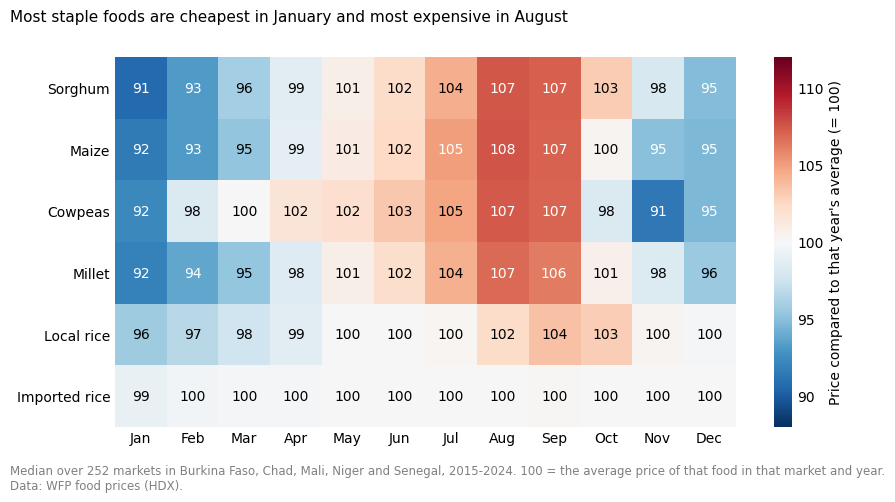

In [130]:
food_names = {"millet": "Millet", "sorghum": "Sorghum", "maize": "Maize", "cowpeas": "Cowpeas",
              "rice_local": "Local rice", "rice_imported": "Imported rice"}
months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

fig, ax = plt.subplots(figsize=(10, 4.8))

# heatmap with a number in every cell
im = ax.imshow(heat.values, cmap="RdBu_r", vmin=88, vmax=112, aspect="auto")
for i in range(len(heat)):
    for j in range(12):
        value = heat.values[i, j]
        ax.text(j, i, f"{value:.0f}", ha="center", va="center",
                color="white" if abs(value - 100) > 5 else "black")

ax.set_xticks(range(12))
ax.set_xticklabels(months)
ax.set_yticks(range(len(heat)))
ax.set_yticklabels([food_names[f] for f in heat.index])
ax.tick_params(length=0)   # no small tick lines
for side in ["top", "right", "bottom", "left"]:
    ax.spines[side].set_visible(False)

cbar = fig.colorbar(im, ax=ax, label="Price compared to that year's average (= 100)")
cbar.outline.set_visible(False)   # no black frame
cbar.ax.tick_params(length=0)     # no small tick lines
fig.suptitle("Most staple foods are cheapest in January and most expensive in August",
             x=0.02, ha="left", fontsize=11)
fig.text(0.02, -0.02, f"Median over {seasonal['market_id'].nunique()} markets in Burkina Faso, Chad, Mali, Niger and Senegal, 2015-2024. "
         "100 = the average price of that food in that market and year.\nData: WFP food prices (HDX).",
         fontsize=8.5, color="grey")
plt.savefig("fig1_heatmap_numbers.png", dpi=300, bbox_inches="tight")
plt.show()

## Step 3: price and hunger per year

**Price:** only millet (sold in the most markets, in all 5 countries). I use the team's `price_index`: each market's price divided by its own 2019 average, × 100. So 100 = the 2019 price, 170 = 70% more expensive than in 2019. This way cheap and expensive markets can be combined. One number per year = the median over all millet markets and months.

**Hunger:** Cadre Harmonisé, people in phase 3–5 / population analysed in **Jun–Aug** (the lean season), all 5 countries together.
- Jun–Aug is **only ever a forecast** in the Cadre Harmonisé
- I remove the 13 "current Jun–Aug" rows (only Burkina Faso June 2020), so every year is the same kind of number

In [131]:
# hunger: % of people in phase 3-5 in Jun-Aug, per year
ch = ch[(ch["reference_year"] >= 2015) & (ch["reference_year"] <= 2024)]
ch = ch[~((ch["chtype"] == "current") & (ch["reference_label"] == "Jun-Aug"))]
lean = ch[ch["reference_label"] == "Jun-Aug"].groupby("reference_year")[["phase35", "population_analysed"]].sum()
hunger_year = lean["phase35"] / lean["population_analysed"] * 100

# price: median millet price index (2019 = 100) per year
millet = prices[(prices["food"] == "millet") & prices["price_index"].notna()]
price_year = millet.groupby("year")["price_index"].median()

years = pd.DataFrame({"millet price (2019 = 100)": price_year, "hunger Jun-Aug %": hunger_year})
rho, p = spearmanr(years.iloc[:, 0], years.iloc[:, 1])
print(f"Spearman rho = {rho:.2f} (p = {p:.4f}, {len(years)} years)")
years.round(1).T

Spearman rho = 0.92 (p = 0.0002, 10 years)


,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
millet price (2019 = 100),100.8,101.3,115.6,119.8,99.8,111.3,123.7,175.9,163.9,171.4
hunger Jun-Aug %,5.0,4.4,4.8,5.1,3.8,6.9,8.9,12.3,10.2,10.5


## Figure 2: bar charts

**Research question:** Is hunger the biggest in the years when food is the most expensive?

**Design rationale.** I use **two bar charts on top of each other with the same years below**: millet price on top, hunger below. Price and hunger have different units, so I don't put them on one axis (two y-axes in one chart are easy to misread). You read one year by looking straight down, and bar length is the easiest thing to compare. The price is the team's **price index (2019 = 100)**, not CFA francs, because millet prices differ a lot between markets (a typical price of about 150 CFA/kg in the cheapest market and 320 in the most expensive). The index compares each market with its own 2019 price, so all markets can be combined. Each bar is the **median** over all millet markets (so a few unusual markets don't change the result). Hunger is the share of people in crisis or worse (Cadre Harmonisé phase 3–5) in **Jun–Aug**, the lean season, when it is highest.

The price bars are **deep red**, the same red as "expensive" in the heatmap. The hunger bars are **deep purple**: not red, so red always means price, and not blue, because blue means "cheap" in the heatmap. The **number is written on each bar**, so readers don't have to read it off the axis. Both charts **start at zero**, so the bar lengths are honest. The **title says the finding**. **The chart shows** that the three most expensive years (2022–2024, index 164–176) were also the three hungriest (10.2–12.3%), and the cheapest year (2019, index 100) was the least hungry (3.8%). The ranks match closely (Spearman ρ = 0.92, 10 years). But 2017–2018 were more expensive (116–120) without more hunger (about 5%). **Limitations:** this shows that price and hunger moved together, not that expensive food *caused* the hunger: both rose over time, and 2022 had conflict, drought and world price shocks at once. It is only 10 years, all five countries are combined, the Jun–Aug hunger value is a forecast, and prices are not adjusted for inflation.

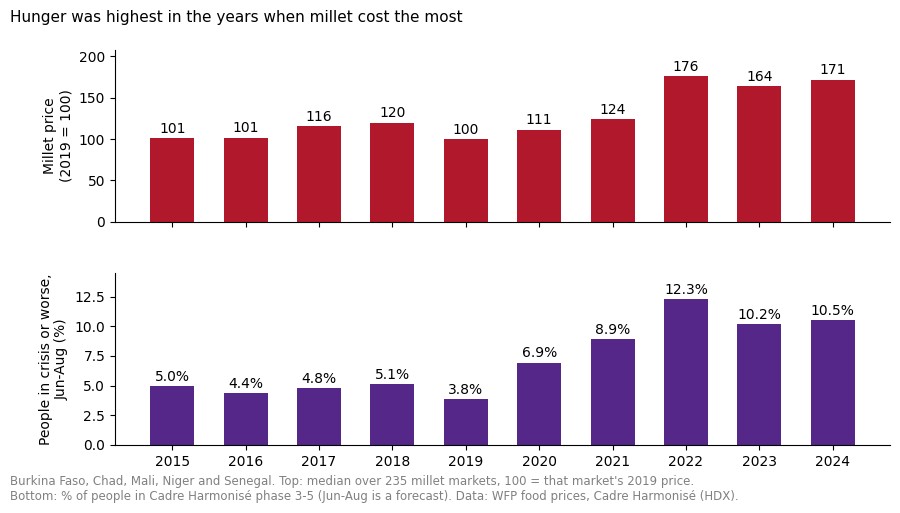

In [132]:
# Figure 2: is hunger the biggest in the years when food is the most expensive?
fig, (a1, a2) = plt.subplots(2, 1, figsize=(10, 5), sharex=True, gridspec_kw={"hspace": 0.3})

# top: millet price per year
a1.bar(price_year.index, price_year.values, color="#b2182b", width=0.6)
for year, value in price_year.items():
    a1.text(year, value + 3, f"{value:.0f}", ha="center", va="bottom")
a1.set_ylim(0, price_year.max() * 1.18)
a1.set_ylabel("Millet price\n(2019 = 100)")

# bottom: hunger per year (Jun-Aug)
a2.bar(hunger_year.index, hunger_year.values, color="#542788", width=0.6)
for year, value in hunger_year.items():
    a2.text(year, value + 0.2, f"{value:.1f}%", ha="center", va="bottom")
a2.set_ylim(0, hunger_year.max() * 1.18)
a2.set_ylabel("People in crisis or worse,\nJun-Aug (%)")
a2.set_xticks(price_year.index)

for a in [a1, a2]:
    a.spines["top"].set_visible(False)
    a.spines["right"].set_visible(False)

fig.subplots_adjust(top=0.9)   # room for the title
fig.suptitle("Hunger was highest in the years when millet cost the most",
             x=0.02, ha="left", fontsize=11)
fig.text(0.02, 0.0, f"Burkina Faso, Chad, Mali, Niger and Senegal. Top: median over {millet['market_id'].nunique()} millet markets, "
         "100 = that market's 2019 price.\nBottom: % of people in Cadre Harmonisé phase 3-5 (Jun-Aug is a forecast). "
         "Data: WFP food prices, Cadre Harmonisé (HDX).",
         fontsize=8.5, color="grey")
plt.savefig("fig2_price_hunger.png", dpi=300, bbox_inches="tight")
plt.show()

## What I found

- Millet, sorghum, maize and cowpeas are cheapest in **January** (index about 91–92) and most expensive in **August** (about 107–108), so about 16–19% more in August. Imported rice hardly changes (99–100).
- The years with the most expensive millet (**2022–2024**) were also the years with the most people in crisis in Jun–Aug (**10.2–12.3%**), and the cheapest year (2019) was the least hungry (3.8%). Spearman ρ = 0.92 over 10 years.
- But it is not perfect: 2017–2018 were more expensive without more hunger.

**Limitations:** correlation ≠ causation (both rose over time, and 2022 had conflict, drought and world price shocks at once); only 10 years; Jun–Aug is only a forecast in the Cadre Harmonisé; all five countries are combined; prices are not adjusted for inflation.